# Import Requirements

In [1]:
# For measuring runtime and suppressing warnings
import time
import warnings

# For data handling and visualisation
import pandas as pd # Imports the external library pandas and assigns it the alias pd
import numpy as np
import matplotlib.pyplot as plt 

# For data preprocessing 
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import StandardScaler

# For performance evaluation: metrics and statistical tools
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from scipy.stats import t

# Machine learning classifiers
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression

# Environment and Experiment Setup

In [2]:
# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')

# Configure pandas' display settings 
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

pd.set_option('display.width', 1000) # To improve readability

In [3]:
# Set key experiment configuration
CONFIG = {
    'file_path': 'dataset_sdn.csv', # Make sure this file is in the same folder as this notebook/script
    'random_state': 324654, # A random popular number
    'test_size': 0.3, # 70%/30% train/test data split
    'num_runs': 10,
    'confidence_level': 0.95 
} 

# Define models
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=CONFIG['random_state']),
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "Neural Network": MLPClassifier(max_iter=500, random_state=CONFIG['random_state']), # Increased max_iter for convergence
    "Naive Bayes": GaussianNB(),
    "Logistic Regression": LogisticRegression(random_state=CONFIG['random_state'], solver='liblinear', max_iter=500)
} 

In [4]:
print("--- SDN DDoS Attack Detection with Processed and Engineered Features and Five ML Classifiers ---")

--- SDN DDoS Attack Detection with Processed and Engineered Features and Five ML Classifiers ---


# Part 1: Load and Preprocess Data

In [5]:
print("\nPart 1: Loading and preprocessing data...")


Part 1: Loading and preprocessing data...


In [6]:
# Load data from local file
print("Loading data from local file...")

try:
    df = pd.read_csv(CONFIG['file_path'])
    print("Data loaded successfully.")
    print("Original dataset shape:", df.shape) # To track changes later
    print("Original column names:", df.columns.tolist()) # To know column names up front
except Exception as e:
    print(f"Error loading data: {e}")
    exit()

# Observe a small sample of the original dataset for a quick look at it/reference
print("Original first few rows:")
df.head() 

Loading data from local file...
Data loaded successfully.
Original dataset shape: (104345, 23)
Original column names: ['dt', 'switch', 'src_ip', 'dst_ip', 'pkt_count', 'byte_count', 'duration', 'duration_nsec', 'tot_duration', 'flows', 'packet_per_massg', 'pktper_flow', 'byte_per_flow', 'pkt_rate', 'pair_flow', 'Protocol', 'port_no', 'tx_bytes', 'rx_bytes', 'tx_kbps', 'rx_kbps', 'tot_kbps', 'label']
Original first few rows:


,dt,switch,src_ip,dst_ip,pkt_count,byte_count,duration,duration_nsec,tot_duration,flows,packet_per_massg,pktper_flow,byte_per_flow,pkt_rate,pair_flow,Protocol,port_no,tx_bytes,rx_bytes,tx_kbps,rx_kbps,tot_kbps,label
0,11425,1,10.0.0.1,10.0.0.8,45304,48294064,100,716000000,1.010000e+11,3,1943,13535,14428310,451,0,UDP,3,143928631,3917,0,0.0,0.0,0
1,11605,1,10.0.0.1,10.0.0.8,126395,134737070,280,734000000,2.810000e+11,2,1943,13531,14424046,451,0,UDP,4,3842,3520,0,0.0,0.0,0
2,11425,1,10.0.0.2,10.0.0.8,90333,96294978,200,744000000,2.010000e+11,3,1943,13534,14427244,451,0,UDP,1,3795,1242,0,0.0,0.0,0
3,11425,1,10.0.0.2,10.0.0.8,90333,96294978,200,744000000,2.010000e+11,3,1943,13534,14427244,451,0,UDP,2,3688,1492,0,0.0,0.0,0
4,11425,1,10.0.0.2,10.0.0.8,90333,96294978,200,744000000,2.010000e+11,3,1943,13534,14427244,451,0,UDP,3,3413,3665,0,0.0,0.0,0


In [7]:
# Remove any whitespace at the beginnings or ends of column names to ensure proper access to columns
df.columns = df.columns.str.strip()

# Harmonise column names so the original Kaggle dataset works directly
column_mapping = {
    'src': 'src_ip', 'dst': 'dst_ip',
    'pktcount': 'pkt_count', 'bytecount': 'byte_count',
    'dur': 'duration', 'dur_nsec': 'duration_nsec', 'tot_dur': 'tot_duration',
    'packetins': 'packet_per_massg',
    'pktperflow': 'pktper_flow', 'byteperflow': 'byte_per_flow',
    'pktrate': 'pkt_rate', 'Pairflow': 'pair_flow',
}
df = df.rename(columns=column_mapping)

# Verify all column names are still unique
if df.columns.duplicated().any():
    raise ValueError(f"These duplicate column names were found: {df.columns[df.columns.duplicated()].tolist()}. Please resolve these manually.")

In [8]:
# Drop rows with NaNs
initial_rows = len(df)
df.dropna(inplace=True) # inplace=True applies the changes directly to df rather than returning a new DataFrame
if initial_rows != len(df):
    print(f"Dropped {initial_rows - len(df)} rows due to NaNs.")

Dropped 506 rows due to NaNs.


In [9]:
# Convert the column 'label' to numerical if it's not already (for reusability) and standardise the positive class as 1 (for changeability)
target_col = 'label'
if target_col in df.columns: # Defensive
    if not pd.api.types.is_numeric_dtype(df[target_col]): # Works with pandas 2 and 3
        df[target_col] = df[target_col].map({'Normal': 0, 'DDoS Attack': 1})
    positive_class_label = 1
else:
    print(f"Target column '{target_col}' not found. Cannot proceed.")
    exit()

In [10]:
# Handle categorical features
for col in ['src_ip', 'dst_ip', 'Protocol']:
    if col in df.columns and not pd.api.types.is_numeric_dtype(df[col]): # Works with pandas 2 and 3
        df[col] = pd.factorize(df[col])[0] # [0] selects the integer codes only from the returned tuple, dropping the mapping

In [11]:
# Detect, flag, and correct invalid negative values
print("\nProcessing for negative values...")

# Define inherently non-negative features
cols_to_check_for_negative = [
    'pkt_count', 'byte_count', 'pkt_rate', 'byte_per_flow', 'delay', 'jitter',
    'tx_kbps', 'rx_kbps', 'tot_kbps', 'duration', 'flows'
]
for col in cols_to_check_for_negative:
    if col in df.columns:
        # Create a Boolean column that flags whether each original value was negative
        df[f'is_negative_{col}'] = (df[col] < 0).astype(int) 
        # Correct the original data by replacing negative values with 0 (the minimum valid value) 
        df[col] = df[col].clip(lower=0)


Processing for negative values...


In [12]:
print("Preprocessing complete.")

Preprocessing complete.


# Part 2: Feature Engineering

In [13]:
print("\nPart 2: Engineering additional features...")

# Create new features capturing short-term trends and fluctuations of existing temporal features by calculating their rolling window mean and standard deviation
rolling_cols = ['pkt_count', 'byte_count', 'pkt_rate', 'byte_per_flow', 'delay', 'jitter', 'tx_kbps', 'rx_kbps', 'tot_kbps']
for col in rolling_cols:
    if col in df.columns:
        df[f'{col}_rolling_mean_5'] = df[col].rolling(window=5, min_periods=1).mean()
        df[f'{col}_rolling_std_5'] = df[col].rolling(window=5, min_periods=1).std().fillna(0)

# Derive network features
if 'pkt_count' in df.columns and 'byte_count' in df.columns:
    df['pkt_byte_ratio'] = df['pkt_count'] / (df['byte_count'] + 1e-9) # (+ 1e-9) is a small, effectless addition to the denominator to prevent division by zero
    
if 'pkt_rate' in df.columns and 'byte_per_flow' in df.columns:
    df['pkt_rate_change'] = df['pkt_rate'].diff().fillna(0) 
    df['byte_per_flow_change'] = df['byte_per_flow'].diff().fillna(0) 

if 'flows' in df.columns and 'pkt_count' in df.columns:
    df['flow_density'] = df['flows'] / (df['pkt_count'] + 1e-9)

if 'tot_kbps' in df.columns and 'pkt_count' in df.columns:
    df['kbps_per_pkt'] = df['tot_kbps'] / (df['pkt_count'] + 1e-9)

if 'tot_duration' in df.columns and 'flows' in df.columns:
    df['inter_arrival_time_proxy'] = df['tot_duration'] / (df['flows'] + 1e-9)

print("Feature engineering complete.")


Part 2: Engineering additional features...
Feature engineering complete.


In [14]:
# Define the full/final list of features to use
all_features = [
    'switch', 'host', 'src_ip', 'dst_ip', 'pkt_count', 'byte_count', 'duration',
    'duration_nsec', 'tot_duration', 'flows', 'packet_per_massg', 'pktper_flow',
    'byte_per_flow', 'pkt_rate', 'pair_flow', 'Protocol', 'port_no', 'tx_bytes',
    'rx_bytes', 'tx_kbps', 'rx_kbps', 'tot_kbps', 'delay', 'jitter',
    'packet_loss_rate', 'pkt_count_rolling_mean_5', 'pkt_count_rolling_std_5',
    'byte_count_rolling_mean_5', 'byte_count_rolling_std_5',
    'pkt_rate_rolling_mean_5', 'pkt_rate_rolling_std_5',
    'byte_per_flow_rolling_mean_5', 'byte_per_flow_rolling_std_5',
    'delay_rolling_mean_5', 'delay_rolling_std_5', 'jitter_rolling_mean_5',
    'jitter_rolling_std_5', 'tx_kbps_rolling_mean_5', 'tx_kbps_rolling_std_5',
    'rx_kbps_rolling_mean_5', 'rx_kbps_rolling_std_5',
    'tot_kbps_rolling_mean_5', 'tot_kbps_rolling_std_5',
    'inter_arrival_time_proxy', 'pkt_rate_change', 'byte_per_flow_change',
    'pkt_byte_ratio', 'flow_density', 'kbps_per_pkt',
    'is_negative_pkt_count', 'is_negative_byte_count', 'is_negative_pkt_rate',
    'is_negative_byte_per_flow', 'is_negative_delay', 'is_negative_jitter',
    'is_negative_tx_kbps', 'is_negative_rx_kbps', 'is_negative_tot_kbps',
    'is_negative_duration', 'is_negative_flows'
]
final_features = [f for f in all_features if f in df.columns] # To prevent errors from trying to access features in all_features that may have not been generated in past parts

# Drop zero-variance features to avoid unnecessary computation since they carry no predictive power 
zero_variance_features = [col for col in final_features if df[col].std() == 0]
if zero_variance_features:
    final_features = [f for f in final_features if f not in zero_variance_features]

# Separate (or define) features (X) and target vector (y)
X = df[final_features]
y = df[target_col]

# Checks
print(f"Final features (X) selected: {X.columns.tolist()}")
print(f"Final data shape: {X.shape}")
print(f"Target (y) column: {y.name}")

Final features (X) selected: ['switch', 'src_ip', 'dst_ip', 'pkt_count', 'byte_count', 'duration', 'duration_nsec', 'tot_duration', 'flows', 'packet_per_massg', 'pktper_flow', 'byte_per_flow', 'pkt_rate', 'pair_flow', 'Protocol', 'port_no', 'tx_bytes', 'rx_bytes', 'tx_kbps', 'rx_kbps', 'tot_kbps', 'pkt_count_rolling_mean_5', 'pkt_count_rolling_std_5', 'byte_count_rolling_mean_5', 'byte_count_rolling_std_5', 'pkt_rate_rolling_mean_5', 'pkt_rate_rolling_std_5', 'byte_per_flow_rolling_mean_5', 'byte_per_flow_rolling_std_5', 'tx_kbps_rolling_mean_5', 'tx_kbps_rolling_std_5', 'rx_kbps_rolling_mean_5', 'rx_kbps_rolling_std_5', 'tot_kbps_rolling_mean_5', 'tot_kbps_rolling_std_5', 'inter_arrival_time_proxy', 'pkt_rate_change', 'byte_per_flow_change', 'pkt_byte_ratio', 'flow_density', 'kbps_per_pkt', 'is_negative_pkt_rate', 'is_negative_byte_per_flow']
Final data shape: (103839, 43)
Target (y) column: label


# Part 3: Train and Evaluate Classifiers

In [15]:
print("\nPart 3: Training and evaluating models...")

results = {name: {'accuracy': [], 'precision': [], 'recall': [], 'f1': []} for name in models.keys()}

print(f"\nEvaluating models over {CONFIG['num_runs']} runs...")
for i in range(CONFIG['num_runs']):
    print(f'\nStarting run {i+1} by preparing training/test data')
    
    # Split features (X) and labels (y) into training and test sets
    # random_state=i ensures each run's split is different but reproducible
    # stratify=y maintains the class balance of the full dataset in both sets
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=CONFIG['test_size'], random_state=i, stratify=y 
    )

    # Scale features to prevent scale-sensitive classifiers from biasing towards those with larger numbers (applied to all classifers for consistency and fairness)
    scaler = StandardScaler() # Initialise StandardScaler 
    X_train_scaled = scaler.fit_transform(X_train) # Fit it only on the training data
    X_test_scaled = scaler.transform(X_test)

    for model_name, model in models.items():
        print(f"\nStarting {model_name}")
        start = time.time() # To record the current time (in seconds) before training starts
        model.fit(X_train_scaled, y_train) # Train
        y_pred = model.predict(X_test_scaled) # Evaluate

        # Calculate metrics
        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred, pos_label=positive_class_label, zero_division=0) # zero_division=0 to return 0 instead of an error or NaN when the denominator of the formula is 0
        recall = recall_score(y_test, y_pred, pos_label=positive_class_label, zero_division=0)
        f1 = f1_score(y_test, y_pred, pos_label=positive_class_label, zero_division=0)

        results[model_name]['accuracy'].append(accuracy)
        results[model_name]['precision'].append(precision)
        results[model_name]['recall'].append(recall)
        results[model_name]['f1'].append(f1)
        end = time.time() # To record the current time (in seconds) after training ends
        print(f"\nCompleted in {end-start}s")


Part 3: Training and evaluating models...

Evaluating models over 10 runs...

Starting run 1 by preparing training/test data

Starting Decision Tree

Completed in 0.7557737827301025s

Starting K-Nearest Neighbors

Completed in 1.3448681831359863s

Starting Neural Network

Completed in 17.278825998306274s

Starting Naive Bayes

Completed in 0.027598142623901367s

Starting Logistic Regression

Completed in 0.9166600704193115s

Starting run 2 by preparing training/test data

Starting Decision Tree

Completed in 0.7914018630981445s

Starting K-Nearest Neighbors

Completed in 1.292470932006836s

Starting Neural Network

Completed in 11.99525785446167s

Starting Naive Bayes

Completed in 0.022327184677124023s

Starting Logistic Regression

Completed in 0.9172878265380859s

Starting run 3 by preparing training/test data

Starting Decision Tree

Completed in 0.86698317527771s

Starting K-Nearest Neighbors

Completed in 1.297847032546997s

Starting Neural Network

Completed in 12.7537519931793

# Part 4: Summary Statistics & Output with Confidence Intervals

In [16]:
print("\nPart 4: Summary Statistics Across All Runs")

degrees_of_freedom = CONFIG['num_runs'] - 1
t_value = t.ppf(1 - (1 - CONFIG['confidence_level']) / 2, degrees_of_freedom)

for model_name, model_results in results.items():
    print(f"\n--- {model_name} ---")

    # Calculate and print Mean, Std Dev, Margin of Error, and Confidence Interval for each metric
    for metric_name in ['accuracy', 'precision', 'recall', 'f1']:
        mean_val = np.mean(model_results[metric_name])
        std_val = np.std(model_results[metric_name], ddof=1)

        if CONFIG['num_runs'] > 1:
            # Calculate standard error and margin of error using t-distribution
            standard_error = std_val / np.sqrt(CONFIG['num_runs'])
            margin_of_error = t_value * standard_error
            lower_bound = mean_val - margin_of_error
            upper_bound = mean_val + margin_of_error

            print(f"Mean {metric_name.capitalize()}: {mean_val:.4f} (Std: {std_val:.4f})")
            print(f"95% Confidence Interval for Mean {metric_name.capitalize()}: [{lower_bound:.4f}, {upper_bound:.4f}]")
            print(f"Margin of Error: {margin_of_error:.4f}")
        else:
            print(f"Mean {metric_name.capitalize()}: {mean_val:.4f}")
            print("Confidence interval not calculated for a single run.")

all_results_dfs = []
for model_name, model_results in results.items():
    df_results = pd.DataFrame({
        'Model': [model_name] * CONFIG['num_runs'],
        'Run': list(range(1, CONFIG['num_runs'] + 1)),
        'Accuracy': model_results['accuracy'],
        'Precision_DDoS': model_results['precision'],
        'Recall_DDoS': model_results['recall'],
        'F1_Score_DDoS': model_results['f1']
    })
    all_results_dfs.append(df_results)
df_all_results = pd.concat(all_results_dfs, ignore_index=True)
df_all_results.to_csv("all_models_performance_summary.csv", index=False)

print("\nPerformance results saved to 'all_models_performance_summary.csv'")


Part 4: Summary Statistics Across All Runs

--- Decision Tree ---
Mean Accuracy: 0.9994 (Std: 0.0002)
95% Confidence Interval for Mean Accuracy: [0.9993, 0.9995]
Margin of Error: 0.0001
Mean Precision: 0.9992 (Std: 0.0003)
95% Confidence Interval for Mean Precision: [0.9990, 0.9994]
Margin of Error: 0.0002
Mean Recall: 0.9994 (Std: 0.0002)
95% Confidence Interval for Mean Recall: [0.9992, 0.9996]
Margin of Error: 0.0002
Mean F1: 0.9993 (Std: 0.0002)
95% Confidence Interval for Mean F1: [0.9991, 0.9994]
Margin of Error: 0.0001

--- K-Nearest Neighbors ---
Mean Accuracy: 0.9766 (Std: 0.0008)
95% Confidence Interval for Mean Accuracy: [0.9760, 0.9771]
Margin of Error: 0.0005
Mean Precision: 0.9680 (Std: 0.0015)
95% Confidence Interval for Mean Precision: [0.9669, 0.9691]
Margin of Error: 0.0011
Mean Recall: 0.9721 (Std: 0.0013)
95% Confidence Interval for Mean Recall: [0.9711, 0.9730]
Margin of Error: 0.0009
Mean F1: 0.9700 (Std: 0.0010)
95% Confidence Interval for Mean F1: [0.9693, 0.97

# Part 5: Plotting Results


Part 5: Plotting Results...
Plots saved to 'all_models_performance_plots.png'


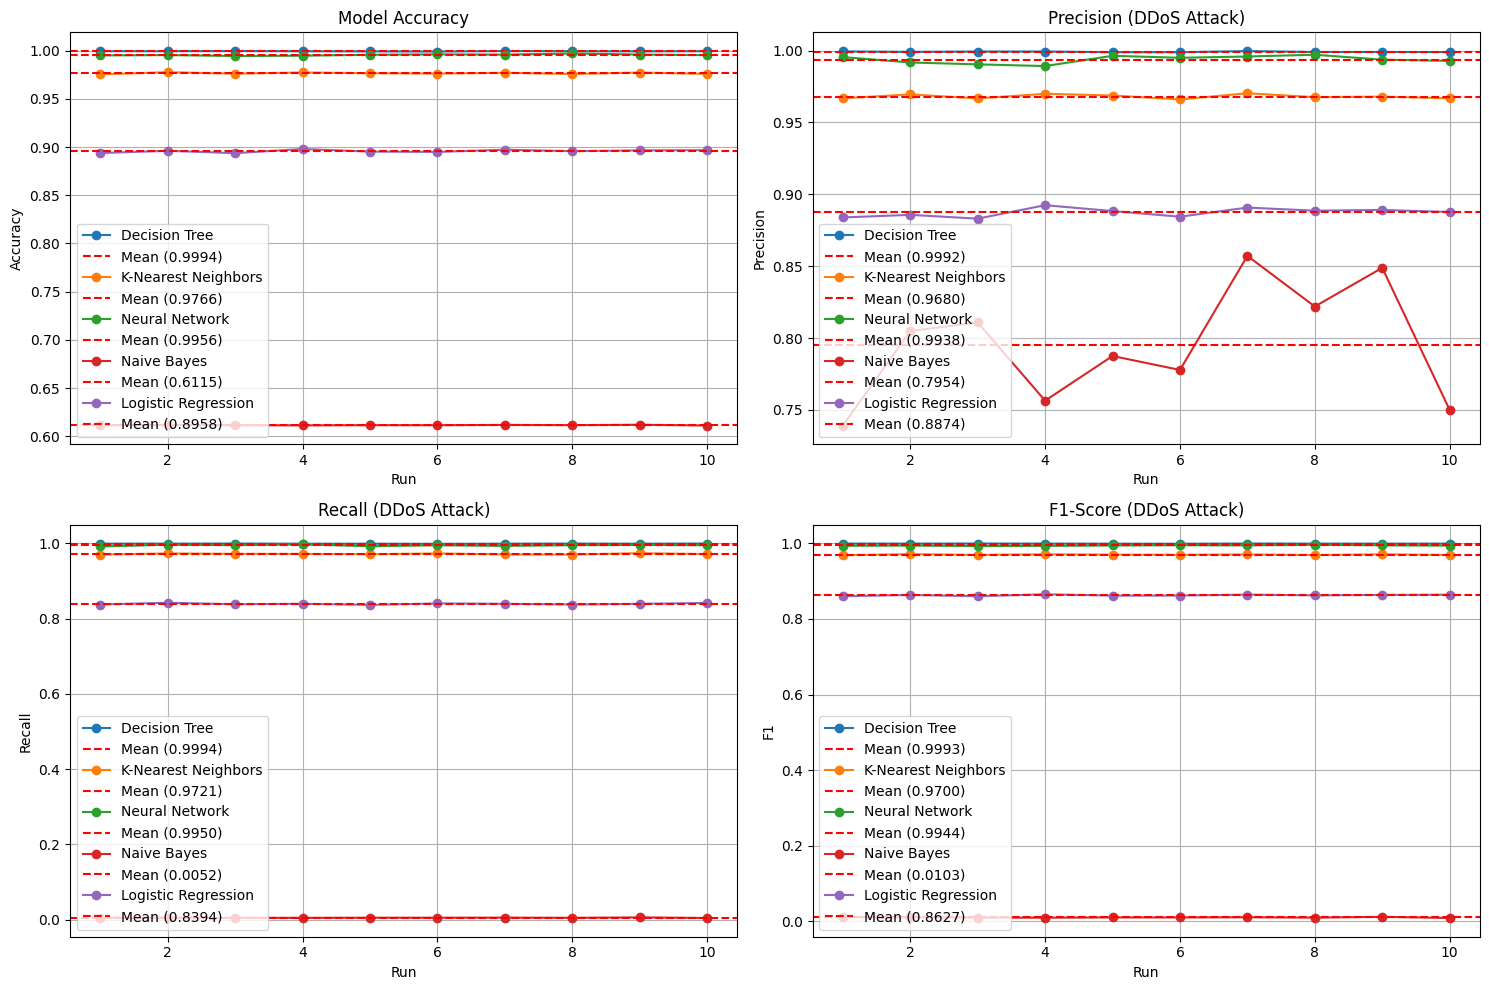

In [17]:
print("\nPart 5: Plotting Results...")

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 10))
metrics = ['accuracy', 'precision', 'recall', 'f1']
titles = ['Model Accuracy', 'Precision (DDoS Attack)', 'Recall (DDoS Attack)', 'F1-Score (DDoS Attack)']
for i, metric in enumerate(metrics):
    ax = axes.flatten()[i]
    for model_name, model_results in results.items():
        mean_val = np.mean(model_results[metric])
        ax.plot(range(1, CONFIG['num_runs'] + 1), model_results[metric], marker='o', label=f'{model_name}')
        ax.axhline(mean_val, color='r', linestyle='--', label=f'Mean ({mean_val:.4f})')
    ax.set_title(titles[i])
    ax.set_xlabel('Run')
    ax.set_ylabel(metric.capitalize().replace('_', '-'))
    ax.legend(loc='lower left')
    ax.grid(True)

plt.tight_layout()
plt.savefig("all_models_performance_plots.png")

print("Plots saved to 'all_models_performance_plots.png'")